# AIVS AI Watchlist: the AI and statistics behind early warning

This notebook shows, step by step, how the **AI Watchlist** in AIVS (AI Information Verification System) finds activity that deserves an analyst's attention in a set of public posts. It uses the same rules and thresholds as the application.

**What it covers:** loading data → cleaning → keyword matching → sentiment (a model trained here, plus an optional pretrained transformer) → narrative clustering → posting frequency → anomaly detection → alert generation → charts → checking the alerts against known answers → limitations.

**Two datasets, both stated honestly**

| | Dataset | What it is | Used for |
|---|---|---|---|
| 1 | AIVS watchlist demonstration data | **Synthetic**: 1,000 invented posts generated by AIVS (`server/lib/watch-demo.js`, seed 7), with planted patterns at known times | Matching, clustering, spikes, alerts. Because the answers are known, the alerts can be checked. |
| 2 | TweetEval, sentiment task (SemEval-2017) | **Real public tweets** with human labels, from the authors' GitHub repository | Training and testing the sentiment model |

**How to run:** in Google Colab choose *Runtime → Run all*. Only the standard Colab libraries are needed (pandas, scikit-learn, matplotlib). TweetEval is downloaded from GitHub. The optional transformer step downloads a model from Hugging Face and is skipped automatically if that is not possible.

> Alerts are leads for a human analyst. Sentiment, repetition and coordination signals are never proof that something is false or that anyone is manipulating information.

In [1]:
import re, math, json, hashlib, datetime, urllib.request, io, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter, defaultdict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, silhouette_score
pd.set_option("display.max_colwidth", 120)
print("pandas", pd.__version__)

pandas 3.0.5


## 1. Load dataset 1: the AIVS watchlist demonstration data (synthetic)

- **Source:** generated by the AIVS code itself (same algorithm, same seed). The function below is a line-for-line copy of `server/lib/watch-demo.js`. The fingerprint printed at the end is the same one AIVS produces, so the notebook and the application analyse identical posts. The same posts are in `training/watch-demo-posts.csv`.
- **Collection date:** not applicable (generated). The posts are dated 1–7 October 2026.
- **Size:** 1,000 posts.
- **Planted patterns (the "answers"):**
  1. From 14:00 UTC on day 6 (6 October), about 70 posts in two hours claim that ballot boxes were burned. This is a new narrative that appears only 3 times earlier.
  2. At 10:00 UTC on day 5 (5 October), 12 new accounts post the same "share before they delete this" message within 6 minutes.
  3. Everything else is ordinary background discussion at a normal daily rhythm.
- **Limitations:** the posts are invented, the wording is simpler and more repetitive than real posts, and there are no real people.

In [2]:
import math, datetime, json
BACKGROUND = [
  ("Voter registration closes on Friday, check your status on the IEBC portal", "en"), ("Long queues at the polling station this morning but people are patient", "en"),
  ("The ballot papers in our ward were delivered on time, officials say", "en"), ("Who is ready for the debate tonight? Election questions on jobs and fees", "en"),
  ("IEBC says tallying will be streamed live from the national centre", "en"), ("Our county election officers are training clerks this week", "en"),
  ("Remember to carry your ID card when you go to vote", "en"), ("Kura yako ni sauti yako, jitokeze kupiga kura", "sw"), ("Foleni ni ndefu lakini watu wametulia kituoni", "sw"),
  ("Matokeo ya uchaguzi yatatangazwa na IEBC pekee", "sw"), ("The voting process in our village was calm and orderly", "en"), ("Observers praised the voting arrangements in the county", "en"),
  ("I hope the election results are announced quickly and fairly", "en"), ("Turnout looks lower than last time in our polling centre", "en"), ("Ballot boxes were sealed in front of agents, all parties present", "en"),
  ("Football: great match last night, the league is getting exciting", "en"), ("Rain expected in the afternoon, carry an umbrella", "en"), ("Fuel prices went up again this week", "en")]
PLACES = ["Kiwanja", "Mlima Ward", "Ziwa Centre", "Sokoni", "Bondeni"]
SPIKE = ["Ballot boxes burned in {p} last night, the election is being stolen!", "Breaking: ballot boxes burned at {p} polling centre, share widely", "They burned ballot boxes in {p}, IEBC is hiding it",
  "Video shows ballot boxes burned in {p}, why is nobody talking about this", "Masanduku ya kura yamechomwa {p}, uchaguzi umeibiwa", "Ballot boxes burned in {p}? I want IEBC to explain"]
SYNC = "URGENT: IEBC officials caught changing results in {p}. Share before they delete this! #ElectionTruth https://example.invalid/synthetic-results"
def iso(ms):
    d = datetime.datetime.fromtimestamp(ms // 1000, tz=datetime.timezone.utc)
    return d.strftime("%Y-%m-%dT%H:%M:%S.") + f"{ms % 1000:03d}Z"
def watch_demo_rows(seed=7, start="2026-10-01T00:00:00Z"):
    st = {"s": seed & 0xFFFFFFFF}
    def rand():
        st["s"] = (st["s"] * 1664525 + 1013904223) & 0xFFFFFFFF
        return st["s"] / 4294967296
    pick = lambda a: a[math.floor(rand() * len(a))]
    t0 = int(datetime.datetime.fromisoformat(start.replace("Z", "+00:00")).timestamp() * 1000)
    acc = lambda n: f"voter_{n:03d}"
    rows = []
    for h in range(7 * 24):
        hour = h % 24
        n = 7 + math.floor(rand() * 5) if 7 <= hour <= 21 else math.floor(rand() * 3)
        for _ in range(n):
            text, lang = pick(BACKGROUND); t = t0 + h * 3600000 + math.floor(rand() * 3600000)
            account = acc(1 + math.floor(rand() * 400)); tx = f"{text} #Election2026" if rand() < 0.15 else text
            rows.append({"account": account, "posted_at": iso(t), "text": tx, "language": lang, "platform": pick(["X", "Facebook", "TikTok"]), "likes": math.floor(rand() * 40)})
    while len(rows) > 915: del rows[math.floor(rand() * len(rows))]
    for i in range(3):
        s = pick(SPIKE); p = pick(PLACES)
        rows.append({"account": acc(500 + i), "posted_at": iso(t0 + (2 + i) * 86400000 + 12 * 3600000), "text": s.replace("{p}", p), "language": "en", "platform": "X", "likes": 3})
    sync = t0 + 4 * 86400000 + 10 * 3600000
    for i in range(12):
        rows.append({"account": f"truth_teller_{i + 1:02d}", "posted_at": iso(sync + math.floor((i / 12) * 6 * 60000)), "text": SYNC.replace("{p}", "Sokoni"), "language": "en", "platform": "X", "likes": 1, "account_created_at": iso(sync - 2 * 86400000)})
    spike = t0 + 5 * 86400000 + 14 * 3600000
    for _ in range(70):
        account = acc(600 + math.floor(rand() * 300)); t = spike + math.floor(rand() * 2 * 3600000); s = pick(SPIKE); p = pick(PLACES)
        rows.append({"account": account, "posted_at": iso(t), "text": s.replace("{p}", p), "language": "en", "platform": pick(["X", "Facebook"]), "likes": math.floor(rand() * 200)})
    rows.sort(key=lambda r: r["posted_at"])
    return [{**r, "post_id": f"syn-{seed}-{i + 1}"} for i, r in enumerate(rows)]

rows = watch_demo_rows()
fingerprint = hashlib.sha256(json.dumps(rows, separators=(",", ":"), ensure_ascii=False).encode()).hexdigest()
df = pd.DataFrame(rows)
print(len(df), "posts; SHA-256 of the data:", fingerprint)
df.head()

1000 posts; SHA-256 of the data: 36e7bc90403ac387ceada2ed1b75a5ff34e392a7905bbbd502145db37df2e5d5


,account,posted_at,text,language,platform,likes,post_id,account_created_at
0,voter_020,2026-10-01T01:55:37.133Z,Observers praised the voting arrangements in the county,en,Facebook,2,syn-7-1,NaN
1,voter_390,2026-10-01T01:59:02.173Z,Long queues at the polling station this morning but people are patient,en,Facebook,21,syn-7-2,NaN
2,voter_168,2026-10-01T02:46:47.324Z,Turnout looks lower than last time in our polling centre,en,TikTok,14,syn-7-3,NaN
3,voter_334,2026-10-01T03:44:56.893Z,Long queues at the polling station this morning but people are patient,en,X,39,syn-7-4,NaN
4,voter_046,2026-10-01T05:06:28.828Z,Foleni ni ndefu lakini watu wametulia kituoni,sw,TikTok,3,syn-7-5,NaN


## 2. Explore and clean the data

In [3]:
df["posted_at"] = pd.to_datetime(df["posted_at"], utc=True)
print("Period:", df.posted_at.min(), "to", df.posted_at.max())
print("Missing values per column:"); print(df.isna().sum()[lambda s: s > 0])
print("Exact duplicate rows:", df.duplicated(subset=["post_id"]).sum())
print("Posts per platform:"); print(df.platform.value_counts())
print("Language:"); print(df.language.value_counts())
print("Accounts:", df.account.nunique(), "| posts per account (top 5):"); print(df.account.value_counts().head())

Period: 2026-10-01 01:55:37.133000+00:00 to 2026-10-07 23:41:54.320000+00:00
Missing values per column:
account_created_at    988
dtype: int64
Exact duplicate rows: 0
Posts per platform:
platform
X           380
Facebook    330
TikTok      290
Name: count, dtype: int64
Language:
language
en    858
sw    142
Name: count, dtype: int64
Accounts: 439 | posts per account (top 5):
account
voter_275    9
voter_012    7
voter_192    7
voter_182    7
voter_107    7
Name: count, dtype: int64


**Cleaning and NLP preprocessing.** Text is lower-cased. Links are replaced by a placeholder and @mentions are removed. Repeated letters are shortened ("soooo" becomes "sooo"). Short and very common words (stop words, English and Kiswahili) are dropped for clustering. The same normalisation finds identical messages: two posts count as the same message when their normalised text is equal.

In [4]:
STOP = set('''the and for are but not you all any can her was one our out day get has him his how man new now old see two way who did its let put say she too use that with have this will your from they know want been good much some time very when come here just like long make many over such take than them well were what into more only also then there their about would these other which could after first never where those while being every under before again should since through still because
na ya wa kwa ni za la katika hii huu hiyo huo sana hakuna kama lakini pia wao sisi wewe mimi yeye kuna watu leo tena bado kwamba ili hata baada kabla http https'''.split())
def normalise(t):
    t = t.lower(); t = re.sub(r"https?://\S+", " http ", t); t = re.sub(r"(^|\s)@\w+", " ", t)
    t = re.sub(r"(.)\1{3,}", r"\1\1\1", t); return re.sub(r"\s+", " ", t).strip()
def tokens(t): return [w for w in re.split(r"[^\w#]+", normalise(t)) if len(w) >= 3 and w not in STOP and not w.isdigit()]
df["clean"] = df.text.map(normalise)
df["msg_key"] = df.clean.map(lambda t: re.sub(r"[^\w#\s]", " ", t)).map(lambda t: re.sub(r"\s+", " ", t).strip())
df[["text", "clean"]].head(3)

,text,clean
0,Observers praised the voting arrangements in the county,observers praised the voting arrangements in the county
1,Long queues at the polling station this morning but people are patient,long queues at the polling station this morning but people are patient
2,Turnout looks lower than last time in our polling centre,turnout looks lower than last time in our polling centre


## 3. Keyword matching (the watchlist)

The example watchlist from the brief is **Election misinformation**, with the keywords *election, IEBC, voting, ballot*.

- Each keyword is matched as a whole word. A keyword also matches the same word written as a hashtag.
- *football* is excluded, to show how exclusions remove unrelated uses.

In [5]:
TERMS, EXCLUDE = ["election", "IEBC", "voting", "ballot"], ["football"]
term_re = {t: re.compile(r"(^|[^\w])#?" + re.escape(t.lower()) + r"(?!\w)") for t in TERMS + EXCLUDE}
def match(text):
    t = text.lower(); hits = [x for x in TERMS if term_re[x].search(t)]
    return hits if hits and not any(term_re[x].search(t) for x in EXCLUDE) else []
df["terms"] = df.text.map(match); m = df[df.terms.map(len) > 0].copy()
print(f"{len(m)} of {len(df)} posts match the watchlist")
pd.Series([t for ts in m.terms for t in ts]).value_counts().rename("posts").to_frame()

577 of 1000 posts match the watchlist


,posts
IEBC,180
ballot,168
election,152
voting,113


## 4. Sentiment analysis

### 4a. Train and test a sentiment model (TF-IDF + logistic regression)

- **Data:** dataset 2, TweetEval sentiment (Barbieri et al., 2020, *Findings of EMNLP*), from https://github.com/cardiffnlp/tweeteval. It contains English tweets labelled negative, neutral or positive by people.
- **Splits:** the official ones.
  - The **training** split teaches the model.
  - The **validation** split chooses the regularisation strength.
  - The **test** split is used once, at the end. The model never sees it while learning.
- **Measures:** accuracy, precision, recall, F1 and the confusion matrix, compared with a "majority class" baseline that always guesses the most common label.

AIVS uses the same method (implemented in JavaScript in `server/ai/textclf.js`). Its stored scores, also measured on the 12,284 test tweets, are shown in **Settings → AI models**. Scikit-learn's implementation differs in small details, so the numbers here are close to the application's but not identical.

In [6]:
BASE = "https://raw.githubusercontent.com/cardiffnlp/tweeteval/main/datasets/sentiment/"
def fetch(name): return urllib.request.urlopen(BASE + name, timeout=60).read().decode("utf-8")
def split(s):
    X = fetch(f"{s}_text.txt").rstrip("\n").split("\n"); y = [int(v) for v in fetch(f"{s}_labels.txt").rstrip("\n").split("\n")]
    assert len(X) == len(y); return X, np.array(y)
LABELS = ["negative", "neutral", "positive"]
Xtr, ytr = split("train"); Xva, yva = split("val"); Xte, yte = split("test")
print(f"TweetEval sentiment: train {len(Xtr)}, validation {len(Xva)}, test {len(Xte)} (downloaded {datetime.date.today()})")
print("Training labels:", dict(zip(LABELS, np.bincount(ytr))))

TweetEval sentiment: train 45615, validation 2000, test 12284 (downloaded 2026-10-26)
Training labels: {'negative': np.int64(7093), 'neutral': np.int64(20673), 'positive': np.int64(17849)}


In [7]:
vec = TfidfVectorizer(preprocessor=normalise, ngram_range=(1, 2), min_df=3, max_features=40000, sublinear_tf=True)
Vtr, Vva, Vte = vec.fit_transform(Xtr), vec.transform(Xva), vec.transform(Xte)
best = None
for C in [0.3, 1, 3]:
    clf = LogisticRegression(C=C, max_iter=2000, class_weight="balanced").fit(Vtr, ytr)
    f1 = precision_recall_fscore_support(yva, clf.predict(Vva), average="macro", zero_division=0)[2]
    print(f"C={C}: validation macro-F1 {f1:.3f}")
    if not best or f1 > best[1]: best = (C, f1, clf)
C, _, clf = best; pred = clf.predict(Vte)
p, r, f, sup = precision_recall_fscore_support(yte, pred, zero_division=0)
print(f"\nChosen C={C}. TEST (used once): accuracy {accuracy_score(yte, pred):.3f}, macro-F1 {f.mean():.3f}, macro-recall {r.mean():.3f}")
print(f"Majority-class baseline accuracy: {(yte == np.bincount(ytr).argmax()).mean():.3f}")
pd.DataFrame({"precision": p, "recall": r, "F1": f, "test examples": sup}, index=LABELS).round(3)

C=0.3: validation macro-F1 0.612


C=1: validation macro-F1 0.638


C=3: validation macro-F1 0.641

Chosen C=3. TEST (used once): accuracy 0.588, macro-F1 0.585, macro-recall 0.598
Majority-class baseline accuracy: 0.483


,precision,recall,F1,test examples
negative,0.563,0.632,0.596,3972
neutral,0.641,0.547,0.590,5937
positive,0.529,0.615,0.569,2375


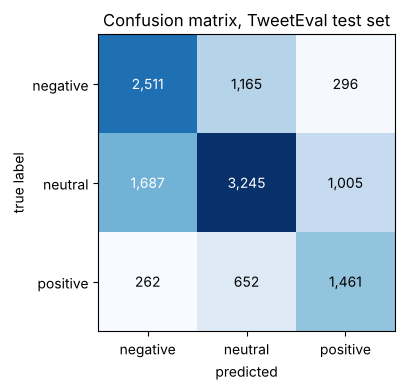

In [8]:
cm = confusion_matrix(yte, pred)
fig, ax = plt.subplots(figsize=(4.6, 4)); ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), LABELS); ax.set_yticks(range(3), LABELS); ax.set_xlabel("predicted"); ax.set_ylabel("true label")
for i in range(3):
    for j in range(3): ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_title("Confusion matrix, TweetEval test set"); plt.tight_layout(); plt.show()

### 4b. Optional: a pretrained transformer (DistilBERT fine-tuned on SST-2)

The cell below loads `distilbert-base-uncased-finetuned-sst-2-english` from Hugging Face and runs it on 300 test tweets that are labelled positive or negative. SST-2 has only those two labels, so neutral tweets are left out of this comparison.

The model is pretrained: it is downloaded and used as it is, not trained in this notebook. If the download is not possible, the cell says so and the notebook continues.

In [9]:
try:
    from transformers import pipeline
    sst = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")
    idx = [i for i in range(len(Xte)) if yte[i] != 1][:300]
    out = sst([Xte[i] for i in idx], truncation=True, batch_size=32)
    acc_t = np.mean([(o["label"] == "POSITIVE") == (yte[i] == 2) for o, i in zip(out, idx)])
    acc_l = np.mean([(clf.predict(vec.transform([Xte[i]]))[0] == 2) == (yte[i] == 2) for i in idx if clf.predict(vec.transform([Xte[i]]))[0] != 1] or [float("nan")])
    print(f"DistilBERT (pretrained, no training here): accuracy {acc_t:.3f} on {len(idx)} positive/negative test tweets")
    print(f"Our TF-IDF model on the same tweets (when it did not answer neutral): accuracy {acc_l:.3f}")
except Exception as e:
    print("Skipped: the pretrained transformer could not be loaded here (", type(e).__name__, str(e)[:120], ").")
    print("In Google Colab this normally works; the rest of the notebook does not depend on it.")

Skipped: the pretrained transformer could not be loaded here ( ModuleNotFoundError No module named 'transformers' ).
In Google Colab this normally works; the rest of the notebook does not depend on it.


### 4c. Sentiment of the watchlist's posts over time

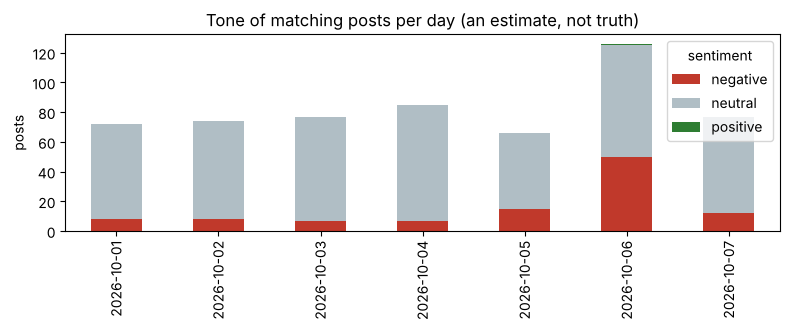

sentiment
neutral     0.813
negative    0.185
positive    0.002
Name: proportion, dtype: float64


In [10]:
m["sentiment"] = [LABELS[k] for k in clf.predict(vec.transform(m.text))]
daily = m.groupby([m.posted_at.dt.date, "sentiment"]).size().unstack(fill_value=0).reindex(columns=LABELS, fill_value=0)
ax = daily.plot(kind="bar", stacked=True, figsize=(8, 3.4), color=["#c0392b", "#b0bec5", "#2e7d32"]); ax.set_xlabel(""); ax.set_ylabel("posts")
ax.set_title("Tone of matching posts per day (an estimate, not truth)"); plt.tight_layout(); plt.show()
print(m.sentiment.value_counts(normalize=True).round(3))

## 5. Narrative clustering (TF-IDF + k-means)

Posts are turned into TF-IDF vectors and grouped with k-means. The number of groups *k* is chosen with the silhouette score, which measures how well each post fits its own group compared with the nearest other group.

The most distinctive words and an example post describe each group. A human reads the examples to decide what each narrative is.

In this synthetic data many posts reuse the same sentences. The silhouette score therefore keeps rising with *k*, and the largest *k* tried is chosen. With real posts it usually peaks at a moderate *k*.

In [11]:
tv = TfidfVectorizer(tokenizer=tokens, lowercase=False, token_pattern=None, ngram_range=(1, 2), min_df=2)
V = tv.fit_transform(m.text); scores = {}
for k in range(4, 13):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(V); scores[k] = silhouette_score(V, km.labels_, sample_size=min(2000, V.shape[0]), random_state=0)
k = max(scores, key=scores.get); km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(V); m["cluster"] = km.labels_
print("silhouette by k:", {a: round(b, 3) for a, b in scores.items()}, "→ k =", k)
terms = np.array(tv.get_feature_names_out()); rows_ = []
for c in range(k):
    top = terms[np.argsort(-km.cluster_centers_[c])[:6]]; ex = m[m.cluster == c].text.iloc[0]
    rows_.append({"cluster": c, "posts": int((m.cluster == c).sum()), "top words": ", ".join(top), "example": ex})
pd.DataFrame(rows_).sort_values("posts", ascending=False)

silhouette by k: {4: 0.31, 5: 0.404, 6: 0.465, 7: 0.555, 8: 0.627, 9: 0.683, 10: 0.754, 11: 0.802, 12: 0.834} → k = 12


,cluster,posts,top words,example
10,10,62,"burned, boxes burned, ballot boxes, boxes, ballot, mlima ward",Ballot boxes burned in Sokoni? I want IEBC to explain
2,2,61,"arrangements, arrangements county, praised, praised voting, observers praised, observers",Observers praised the voting arrangements in the county
1,1,57,"agents parties, agents, boxes sealed, parties, parties present, present","Ballot boxes were sealed in front of agents, all parties present #Election2026"
4,4,53,"election questions, debate, debate tonight, questions jobs, questions, jobs fees",Who is ready for the debate tonight? Election questions on jobs and fees
6,6,52,"iebc says, national, live national, national centre, live, tallying",IEBC says tallying will be streamed live from the national centre
5,5,52,"calm, calm orderly, process village, process, orderly, village",The voting process in our village was calm and orderly
9,9,51,"county election, election officers, clerks week, clerks, officers, officers training",Our county election officers are training clerks this week
3,3,51,"pekee, matokeo, matokeo uchaguzi, iebc pekee, uchaguzi yatatangazwa, uchaguzi",Matokeo ya uchaguzi yatatangazwa na IEBC pekee
0,0,49,"ballot papers, delivered officials, delivered, papers, papers ward, ward delivered","The ballot papers in our ward were delivered on time, officials say"
7,7,40,"check status, check, closes, closes friday, portal, iebc portal","Voter registration closes on Friday, check your status on the IEBC portal"


## 6. Posting frequency

Matching posts are counted per hour. The burned-ballot-boxes rise on 6 October should stand out against the normal daily rhythm.

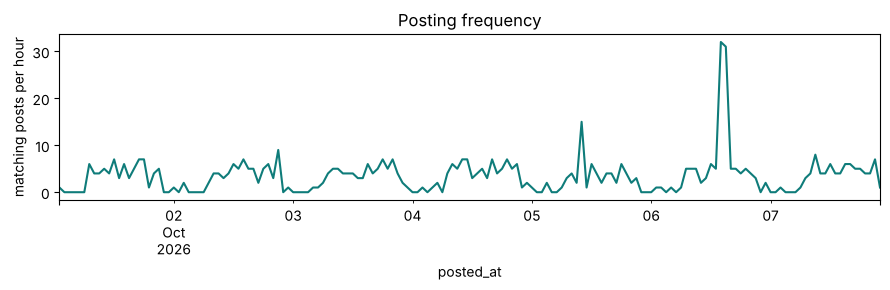

In [12]:
hourly = m.set_index("posted_at").resample("1h").size()
ax = hourly.plot(figsize=(9, 3), color="#0f7c7a"); ax.set_ylabel("matching posts per hour"); ax.set_title("Posting frequency"); plt.tight_layout(); plt.show()

## 7. Anomaly detection

AIVS uses the following rules, all with configurable thresholds. They are the same rules as `server/lib/watch-datasets.js`, with the default settings.

- **Unusual spike (time series against a historical baseline).** A 60-minute window is flagged when all three of these hold:
  - it has at least 10 matching posts;
  - it has at least 3 times the average of the previous 24 windows;
  - it is at least 3 standard deviations above that average.

  A topic that is always busy has a high average, so popularity alone does not trigger an alert.
- **Keyword threshold (the analyst's own rule):** at least 10 matching posts within 60 minutes.
- **Emerging narrative (term bursts).** In 6-hour windows, the rule looks for words or word pairs that meet all four conditions:
  - they appear in at least 8 posts;
  - they appear at 3 times or more their earlier rate;
  - they are 3 standard deviations above their earlier average;
  - at least 8 earlier windows exist, so the usual rate is known.
- **Coordination indicator:** at least 3 different accounts post the same normalised message within 10 minutes.

In [13]:
W = hourly.reindex(pd.date_range(hourly.index.min(), hourly.index.max(), freq="1h"), fill_value=0)
base = W.shift(1).rolling(24)
stats = pd.DataFrame({"posts": W, "mean": base.mean(), "sd": base.std(ddof=0)})
stats["spike"] = (stats.posts >= 10) & (stats.posts >= 3 * stats["mean"]) & (stats.posts >= stats["mean"] + 3 * stats.sd)
stats["threshold"] = stats.posts >= 10
print("Windows flagged as unusual spikes:"); print(stats[stats.spike].round(2))

Windows flagged as unusual spikes:
                           posts  mean    sd  spike  threshold
2026-10-05 10:00:00+00:00     15  3.29  2.39   True       True
2026-10-06 14:00:00+00:00     32  2.58  2.02   True       True
2026-10-06 15:00:00+00:00     31  3.83  6.21   True       True


In [14]:
# emerging narratives: term bursts in 6-hour windows (the watch terms themselves are left out)
def termset(t):
    w = tokens(t); return set(w) | {f"{a} {b}" for a, b in zip(w, w[1:])}
own = {t.lower() for t in TERMS}
m["window6"] = m.posted_at.dt.floor("6h"); wins = sorted(m.window6.unique()); counts = defaultdict(lambda: np.zeros(len(wins)))
for wi, w in enumerate(wins):
    for ts in m[m.window6 == w].text.map(termset):
        for t in ts - own: counts[t][wi] += 1
bursts = []
for wi in range(8, len(wins)):
    for t, a in counts.items():
        c, prev = a[wi], a[:wi]; mean, sd = prev.mean(), prev.std()
        if c >= 8 and c >= 3 * (prev.sum() + 1) / wi and c >= mean + 3 * sd: bursts.append({"window": wins[wi], "term": t, "posts": int(c), "earlier per window": round(mean, 2)})
pd.DataFrame(bursts).sort_values(["window", "posts"], ascending=[True, False]).groupby("window").head(5)

,window,term,posts,earlier per window
0,2026-10-05 06:00:00+00:00,officials,14,1.71
1,2026-10-05 06:00:00+00:00,results,12,1.12
2,2026-10-05 06:00:00+00:00,sokoni,12,0.06
3,2026-10-05 06:00:00+00:00,urgent,12,0.00
4,2026-10-05 06:00:00+00:00,caught changing,12,0.00
19,2026-10-06 12:00:00+00:00,ballot boxes,61,2.00
20,2026-10-06 12:00:00+00:00,boxes,61,2.00
23,2026-10-06 12:00:00+00:00,burned,59,0.14
22,2026-10-06 12:00:00+00:00,boxes burned,49,0.09
21,2026-10-06 12:00:00+00:00,centre,20,1.95


In [15]:
# coordination indicator: many accounts, the same normalised message, within 10 minutes
coord = []
for key, g in m.sort_values("posted_at").groupby("msg_key"):
    t = g.posted_at.values.astype("datetime64[s]").astype(np.int64); accts = g.account.values; best = (0, 0, 0)
    for j in range(len(t)):
        i = np.searchsorted(t, t[j] - 600); n = len(set(accts[i:j + 1]))
        if n > best[0]: best = (n, i, j)
    if best[0] >= 3: coord.append({"accounts": best[0], "minutes": round((t[best[2]] - t[best[1]]) / 60, 1), "from": g.posted_at.iloc[best[1]], "message": g.text.iloc[0][:90]})
pd.DataFrame(coord)

,accounts,minutes,from,message
0,12,5.5,2026-10-05 10:00:00+00:00,URGENT: IEBC officials caught changing results in Sokoni. Share before they delete this! #


## 8. Alert generation

Each detection becomes an alert with a category, time, number of posts, reason, severity and recommended action. The severity rules are the ones documented in AIVS (**AI Watchlist → Overview → How alerts are decided**). Consecutive flagged windows form one event, so one rise gives one alert.

In [16]:
alerts = []
def episodes(flags):
    out, start = [], None
    for ts, f in flags.items():
        if f and start is None: start = ts
        if not f and start is not None: out.append((start, prev)); start = None
        prev = ts
    if start is not None: out.append((start, prev))
    return out
for a, b in episodes(stats.spike):
    seg = stats.loc[a:b]; top = seg.posts.idxmax(); r = seg.loc[top]; ratio = r.posts / max(r["mean"], 1e-9); z = (r.posts - r["mean"]) / r.sd if r.sd else float("inf")
    alerts.append({"category": "Unusual posting spike", "time": top, "posts": int(seg.posts.sum()), "severity": "high" if ratio >= 5 and z >= 5 else "medium",
                   "reason": f"{int(r.posts)} posts in 60 min vs average {r['mean']:.2f} (sd {r.sd:.2f}) in the previous 24 h", "action": "Compare with news and official statements; check the most shared claim."})
for a, b in episodes(stats.threshold):
    seg = stats.loc[a:b]; alerts.append({"category": "Keyword threshold exceeded", "time": a, "posts": int(seg.posts.sum()), "severity": "medium" if seg.posts.max() >= 20 else "low",
                   "reason": f"at least 10 matching posts within 60 min ({int(seg.posts.max())} in the busiest hour)", "action": "Open the posts and see what drove the activity."})
for w, g in pd.DataFrame(bursts).groupby("window") if bursts else []:
    g = g.sort_values("posts", ascending=False); alerts.append({"category": "Emerging narrative", "time": w, "posts": int(g.posts.max()), "severity": "medium" if g.posts.max() >= 16 else "low",
                   "reason": "words suddenly frequent: " + ", ".join(g.term.head(4)), "action": "Read the posts; verify any factual claim."})
for c in coord:
    alerts.append({"category": "Potential coordination indicator", "time": c["from"], "posts": c["accounts"], "severity": "high" if c["accounts"] >= 5 and c["minutes"] <= 10 else "medium",
                   "reason": f"{c['accounts']} accounts posted the same text within {c['minutes']} min", "action": "Lead only: look for innocent explanations; escalate to a reviewer."})
A = pd.DataFrame(alerts).sort_values("time"); A

,category,time,posts,severity,reason,action
4,Emerging narrative,2026-10-05 06:00:00+00:00,14,low,"words suddenly frequent: officials, results, sokoni, urgent",Read the posts; verify any factual claim.
0,Unusual posting spike,2026-10-05 10:00:00+00:00,15,medium,15 posts in 60 min vs average 3.29 (sd 2.39) in the previous 24 h,Compare with news and official statements; check the most shared claim.
2,Keyword threshold exceeded,2026-10-05 10:00:00+00:00,15,low,at least 10 matching posts within 60 min (15 in the busiest hour),Open the posts and see what drove the activity.
6,Potential coordination indicator,2026-10-05 10:00:00+00:00,12,high,12 accounts posted the same text within 5.5 min,Lead only: look for innocent explanations; escalate to a reviewer.
5,Emerging narrative,2026-10-06 12:00:00+00:00,61,medium,"words suddenly frequent: ballot boxes, boxes, burned, boxes burned",Read the posts; verify any factual claim.
1,Unusual posting spike,2026-10-06 14:00:00+00:00,63,high,32 posts in 60 min vs average 2.58 (sd 2.02) in the previous 24 h,Compare with news and official statements; check the most shared claim.
3,Keyword threshold exceeded,2026-10-06 14:00:00+00:00,63,medium,at least 10 matching posts within 60 min (32 in the busiest hour),Open the posts and see what drove the activity.


## 9. Visualisation of the result

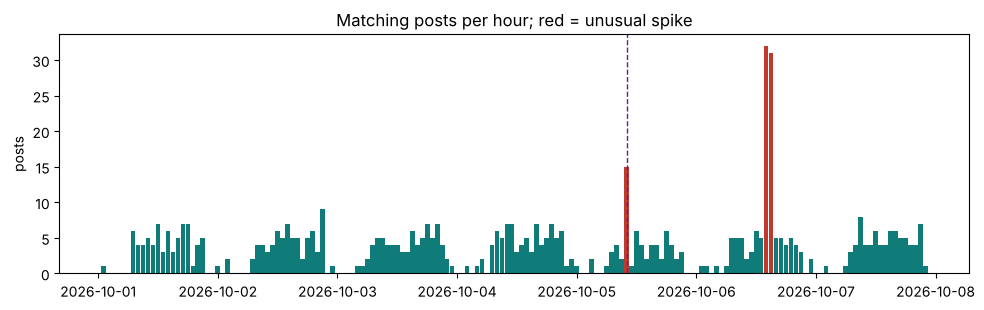

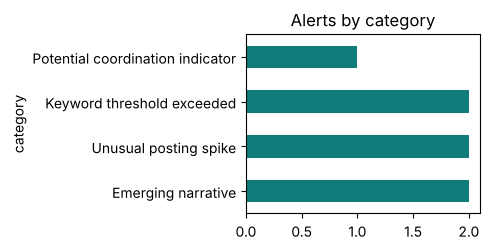

In [17]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(stats.index, stats.posts, width=0.04, color=["#c0392b" if s else "#0f7c7a" for s in stats.spike])
ax.set_title("Matching posts per hour; red = unusual spike"); ax.set_ylabel("posts")
for _, a in A[A.category == "Potential coordination indicator"].iterrows(): ax.axvline(a.time, color="#6a1b9a", ls="--", lw=1)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(5, 2.6)); A.category.value_counts().plot(kind="barh", ax=ax, color="#0f7c7a"); ax.set_title("Alerts by category"); plt.tight_layout(); plt.show()

## 10. Did the alerts find the planted patterns, and nothing else?

The synthetic data has known answers, so every alert can be checked. An alert counts as correct if the period it covers overlaps a planted period:

- day 5, 09:00–11:00 UTC;
- day 6, 13:00–17:00 UTC.

In [18]:
P = [(pd.Timestamp("2026-10-05 09:00", tz="UTC"), pd.Timestamp("2026-10-05 11:00", tz="UTC"), "synchronised posts"), (pd.Timestamp("2026-10-06 13:00", tz="UTC"), pd.Timestamp("2026-10-06 17:00", tz="UTC"), "burned-ballot-boxes rise")]
# each alert covers a period: one hour for spikes and thresholds, six hours for a narrative window, the posts' span for coordination
SPAN = {"Unusual posting spike": pd.Timedelta("1h"), "Keyword threshold exceeded": pd.Timedelta("1h"), "Emerging narrative": pd.Timedelta("6h"), "Potential coordination indicator": pd.Timedelta("10min")}
hit = lambda r: next((n for a, b, n in P if pd.Timestamp(r.time) < b and pd.Timestamp(r.time) + SPAN[r.category] > a), None)
A["planted pattern"] = A.apply(hit, axis=1)
found = {n for n in A["planted pattern"].dropna()}
print(f"Alerts: {len(A)}; in a planted period: {A['planted pattern'].notna().sum()} (precision {A['planted pattern'].notna().mean():.2f})")
print(f"Planted patterns found: {len(found)} of {len(P)} (recall {len(found) / len(P):.2f})")
A[["category", "time", "severity", "planted pattern"]]

Alerts: 7; in a planted period: 7 (precision 1.00)
Planted patterns found: 2 of 2 (recall 1.00)


,category,time,severity,planted pattern
4,Emerging narrative,2026-10-05 06:00:00+00:00,low,synchronised posts
0,Unusual posting spike,2026-10-05 10:00:00+00:00,medium,synchronised posts
2,Keyword threshold exceeded,2026-10-05 10:00:00+00:00,low,synchronised posts
6,Potential coordination indicator,2026-10-05 10:00:00+00:00,high,synchronised posts
5,Emerging narrative,2026-10-06 12:00:00+00:00,medium,burned-ballot-boxes rise
1,Unusual posting spike,2026-10-06 14:00:00+00:00,high,burned-ballot-boxes rise
3,Keyword threshold exceeded,2026-10-06 14:00:00+00:00,medium,burned-ballot-boxes rise


## 11. Limitations and how to read the results

- **Synthetic test data.** The watchlist data are invented and cleaner than real posts. Finding the planted patterns shows that the rules work as designed; it does not measure how they perform on real Kenyan social media.
- **The sentiment model.**
  - It learned from English tweets from 2013–2017; Kiswahili, Sheng and sarcasm are handled poorly. AIVS uses a word list for Kiswahili text and labels which method produced each result.
  - About 60% accuracy on three classes means many individual posts are misjudged. Read the trends, not single labels.
  - Tone is not truth: negative tone is not misinformation, and criticism is not a threat.
- **Historical analysis, not live monitoring.** Imported datasets are analysed by their recorded publication times. Gaps in the data can create or hide spikes. Live monitoring needs a connected, authorised platform API and runs separately in AIVS.
- **Clusters** depend on the vocabulary and on *k*; a human must read the examples.
- **Coordination indicators** are signals. Many accounts posting the same text can be ordinary people sharing a news item or a call to repost. Nothing here identifies who is responsible.
- **Every alert needs human review.** Claims go to AIVS *Verify Information*, where evidence decides and a second person approves.